# Part B: Energy Consumption Forecasting (Time Series)

## Project Overview

The aim of this project is to forecast a building's monthly **gas, electricity and water consumption** for the next **60 months**, so that utility budgets and capacity can be planned ahead. Because each value depends on the values before it, this is a **time series forecasting** problem.

**Dataset:** `CA2-Energy-Consumption-Data.csv`: **397 monthly records (January 1990 – January 2023)**

| Column | Unit |
|---|---|
| `DATE` | Month of the reading (stored as day/month/year) |
| `Gas Consumption (tons)` | tons |
| `Electricity Consumption (MWh)` | MWh |
| `Water Consumption (tons)` | tons |

**Workflow**

1. **Setup & Data Loading:** parsing dates correctly and checking the monthly frequency.
2. **Exploratory Data Analysis (EDA):** outliers, seasonal decomposition and correlation between utilities.
3. **Train / Validation / Test Split:** chronological 80 / 10 / 10 split.
4. **Stationarity Check:** Augmented Dickey-Fuller (ADF) test to decide how much differencing each series needs.
5. **Baseline Models:** several candidate models for each utility.
6. **Hyperparameter Tuning:** grid search on the validation set.
7. **Test Set Evaluation:** final models retrained on train + validation.
8. **60-Month Forecast** with 95% confidence intervals.
9. **Model Improvement Analysis:** the effect of seasonality and of tuning.

## Step 1: Setup & Load Data
### 1.1 Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

GAS, ELEC, WATER = "Gas Consumption (tons)", "Electricity Consumption (MWh)", "Water Consumption (tons)"
UTILITIES = [GAS, ELEC, WATER]
COLORS = {GAS: "#E4572E", ELEC: "#17A398", WATER: "#3D7DCA"}

### 1.2 Loading the Dataset & Parsing Dates

The `DATE` column is written **day-first** (e.g. `1/2/1990` means **1 February 1990**). Without `dayfirst=True`, pandas reads it month-first, and every month turns into a *day in January* (February 1990 becomes 2 January 1990). That would make every time-based plot and date label wrong. The frequency check below confirms the parsed dates are one row per month, with no gaps.

In [2]:
df = pd.read_csv("C:/Users/yyuel/Downloads/CA2-Energy-Consumption-Data.csv")
df["DATE"] = pd.to_datetime(df["DATE"], dayfirst=True)
df = df.set_index("DATE").sort_index()
df.index.freq = pd.infer_freq(df.index)     # set monthly frequency for statsmodels

print("Date range:", df.index.min().strftime("%b %Y"), "to", df.index.max().strftime("%b %Y"))
print("Detected frequency:", df.index.freq, "(MS = month start)")
print("Rows:", len(df), "| Missing values:", int(df.isnull().sum().sum()))
df.head()

Date range: Jan 1990 to Jan 2023
Detected frequency: <MonthBegin> (MS = month start)
Rows: 397 | Missing values: 0


,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
DATE,,,
1990-01-01,18.0,725.1,548.8
1990-02-01,15.8,706.7,640.7
1990-03-01,17.3,624.5,511.1
1990-04-01,18.9,574.7,515.3
1990-05-01,22.0,553.2,488.4


In [3]:
df.describe().round(2)

,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
count,397.00,397.00,397.00
mean,23.79,888.47,484.95
std,4.90,153.88,133.91
min,11.60,553.20,44.40
25%,20.20,771.10,384.40
50%,23.50,897.80,487.40
75%,27.90,1005.20,580.20
max,46.00,1294.00,811.00


**Observations**

- **397 consecutive monthly readings** with **no missing values**.
- **Gas** is the most stable: a mean of 23.8 tons, with half of all months between 20.2 and 27.9 tons. The maximum (**46 tons**) is about **2× the normal level**, which needs checking.
- **Electricity** ranges from **553 to 1,294 MWh**. Its standard deviation (154 MWh) is high mainly because of a **long-term upward trend** (shown in Step 2), not just month-to-month noise.
- **Water** varies the most relative to its size. Its middle 50% spans **384–580 tons**, and its minimum (**44 tons**) is about **10× below** the typical level, which also needs checking.

## Step 2: Exploratory Data Analysis (EDA)
### 2.1 Outlier Detection (Z-score > 3)

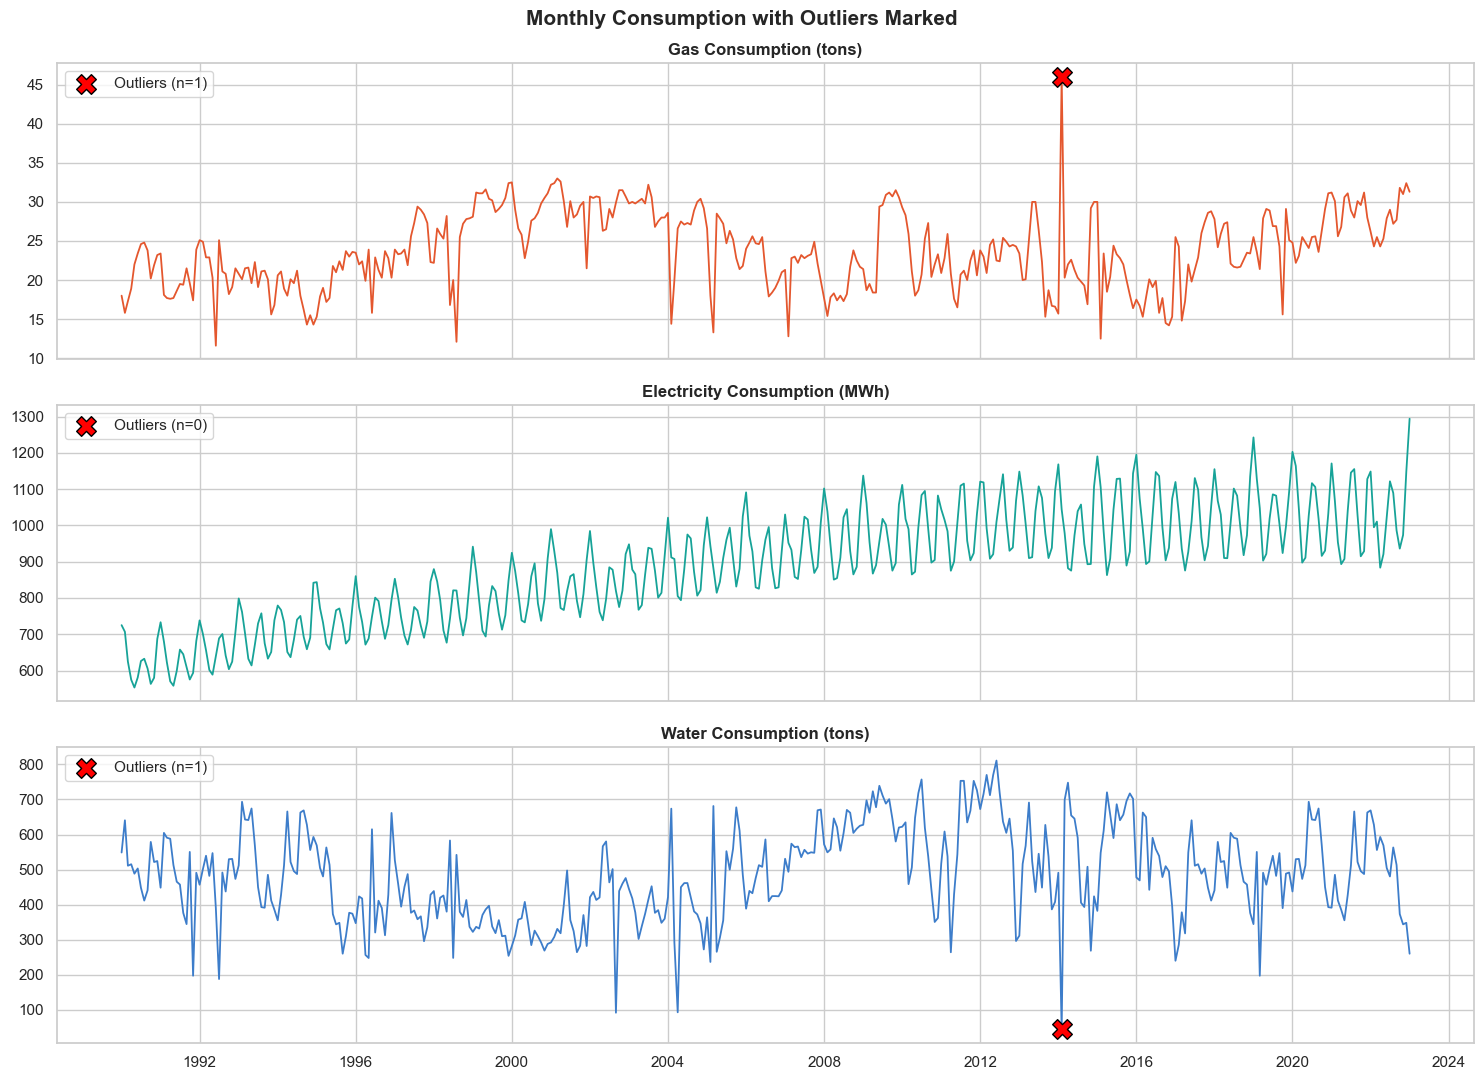

,Utility,Month,Value,Z-score
0,Gas Consumption (tons),Feb 2014,46.0,4.54
1,Water Consumption (tons),Feb 2014,44.4,3.29


In [4]:
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
outlier_rows = []
for ax, u in zip(axes, UTILITIES):
    z = np.abs(stats.zscore(df[u]))
    out = df[z > 3]
    ax.plot(df.index, df[u], color=COLORS[u], linewidth=1.3)
    ax.scatter(out.index, out[u], color="red", s=200, marker="X", edgecolors="black", zorder=5,
               label=f"Outliers (n={len(out)})")
    ax.set_title(u, fontsize=12, fontweight="bold"); ax.legend(loc="upper left")
    for d, v, zz in zip(out.index, out[u], z[z > 3]):
        outlier_rows.append({"Utility": u, "Month": d.strftime("%b %Y"), "Value": v, "Z-score": round(zz, 2)})
plt.suptitle("Monthly Consumption with Outliers Marked", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()
pd.DataFrame(outlier_rows)

- **Gas: 1 outlier.** **46 tons in February 2014** (Z = 4.54), about 2× the usual level.
- **Electricity: no outliers.** Its high values are part of the steady upward trend, not isolated spikes.
- **Water: 1 outlier.** **44 tons**, also in **February 2014** (Z = 3.29).

Both anomalies happen in the **same month**: gas use doubled while water use almost stopped. A single event, such as a plant shutdown, a maintenance period or a metering problem, is more likely than two independent coincidences.

These points are **kept**. They fall in the training period, so keeping them lets us check that the models are not thrown off by one unusual month.

### 2.2 Seasonal Decomposition

Each series is split into **trend**, **seasonal (12-month)** and **residual** parts using additive decomposition.

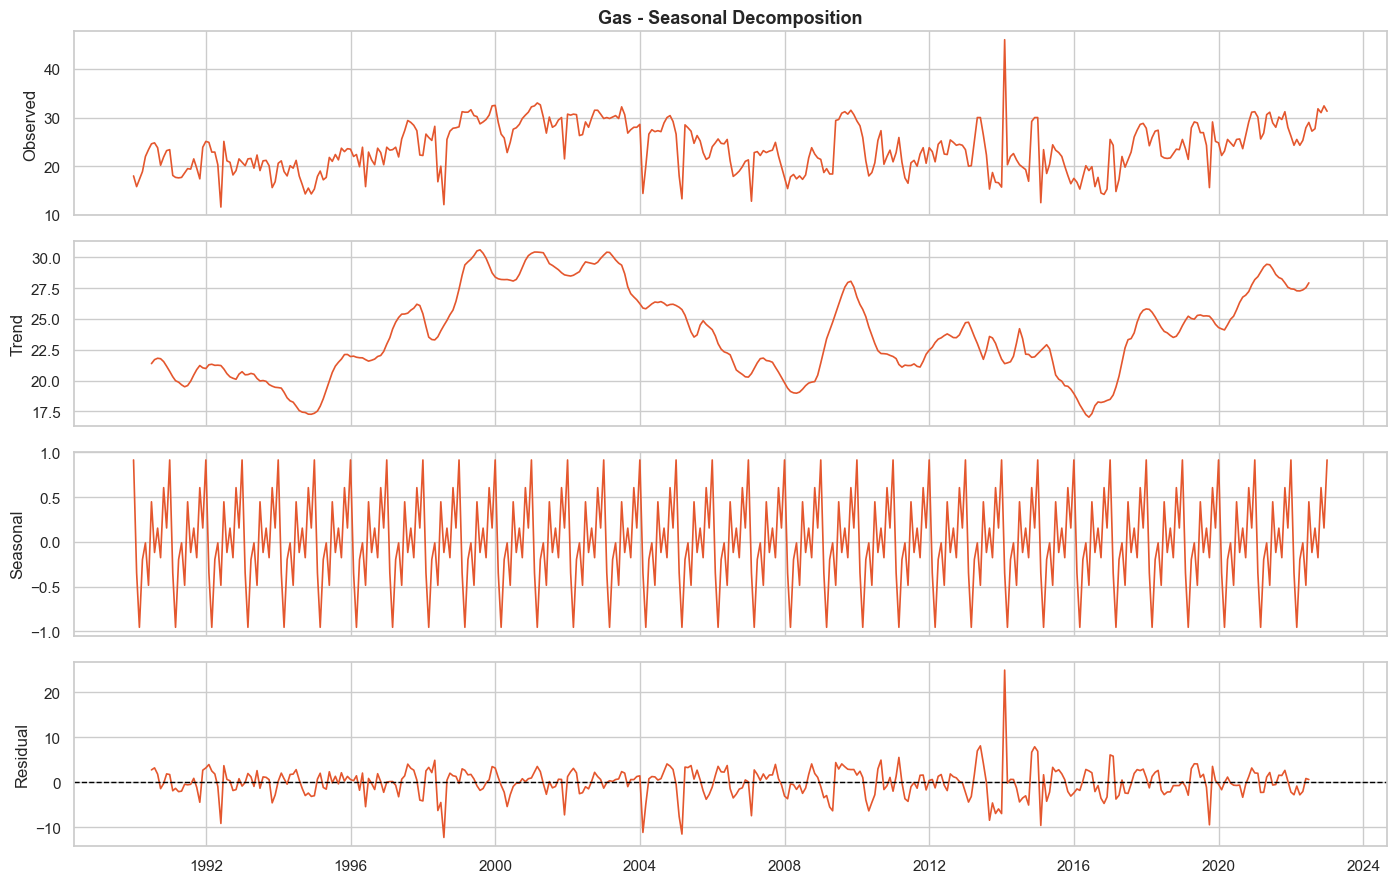

In [5]:
def plot_decomposition(series, title, color):
    dec = seasonal_decompose(series, model="additive", period=12)
    fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
    for ax, part, name in zip(axes, [dec.observed, dec.trend, dec.seasonal, dec.resid],
                              ["Observed", "Trend", "Seasonal", "Residual"]):
        ax.plot(part, color=color, linewidth=1.2); ax.set_ylabel(name)
    axes[3].axhline(0, color="black", linestyle="--", linewidth=1)
    axes[0].set_title(f"{title} - Seasonal Decomposition", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()
    return dec

gas_dec = plot_decomposition(df[GAS], "Gas", COLORS[GAS])

**Gas**
- **Trend:** no long-term growth, but the level **drifts in long waves** rather than staying flat. It is low in the mid-1990s and around 2016 (about 17 tons), high in 2000–2003 (about 30 tons), and has been **rising again since 2017** to about 28–29 tons by 2021.
- **Seasonal:** a very small repeating pattern of about ±1 ton, so seasonality is **weak**.
- **Residual:** mostly within ±5 tons, apart from one large spike at the **February 2014** outlier.

Gas has no seasonality to model, but its slowly drifting level means a model that assumes a constant average may fall behind when the level shifts.

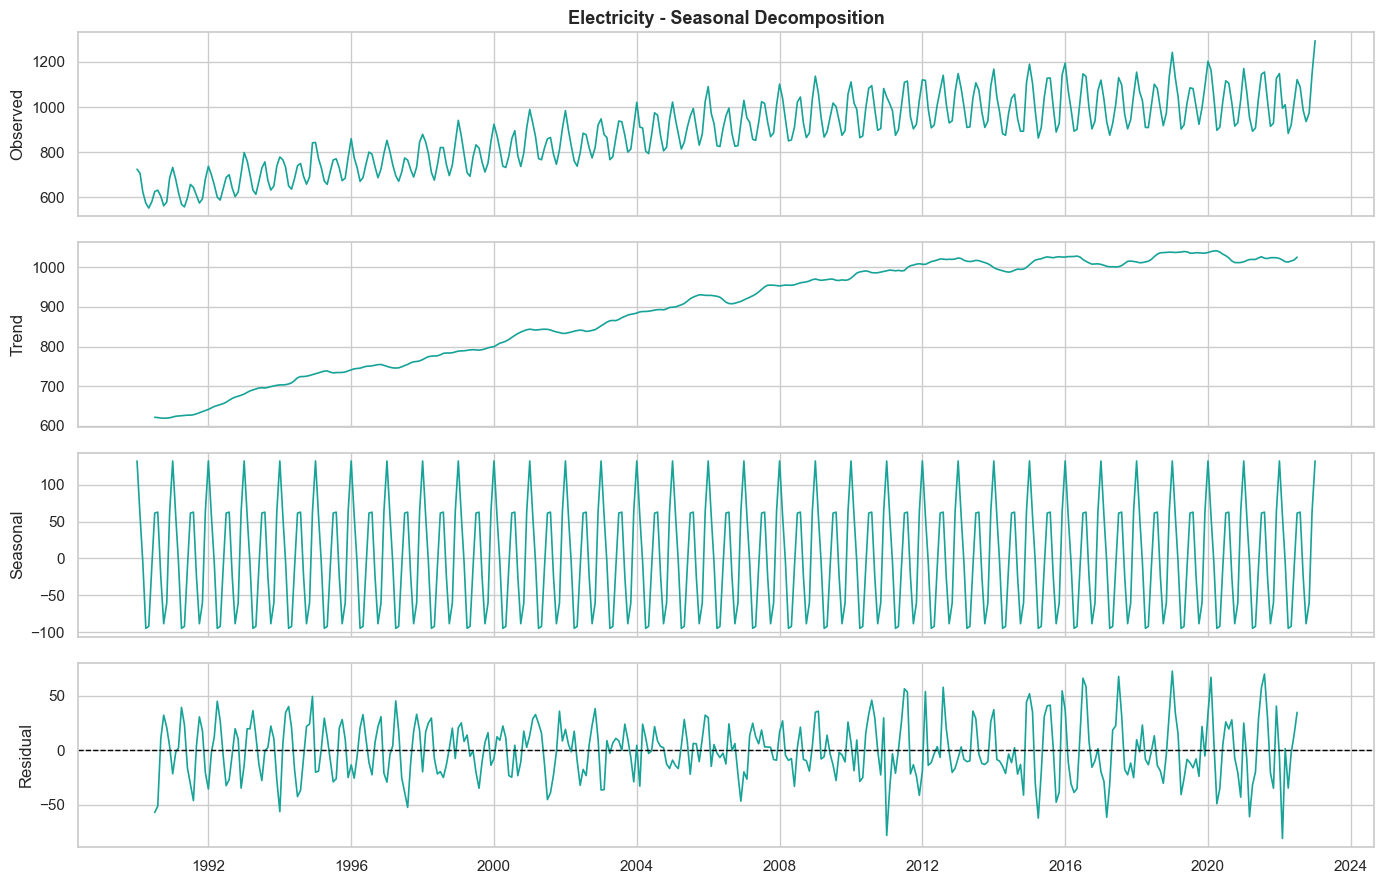

In [6]:
elec_dec = plot_decomposition(df[ELEC], "Electricity", COLORS[ELEC])

**Electricity**
- **Trend:** a steady rise from about **620 MWh (1990) to about 1,030 MWh (around 2013)**. After that it **levels off** at around 1,000–1,040 MWh.
- **Seasonal:** a **strong, regular 12-month cycle** of about −95 to +135 MWh, repeated every year.
- **Residual:** mostly within ±50 MWh, slightly wider after 2010, so trend and seasonality explain most of the variation.

Electricity has both a **trend** and **strong seasonality**, so a seasonal model (SARIMA or Holt-Winters) is needed.

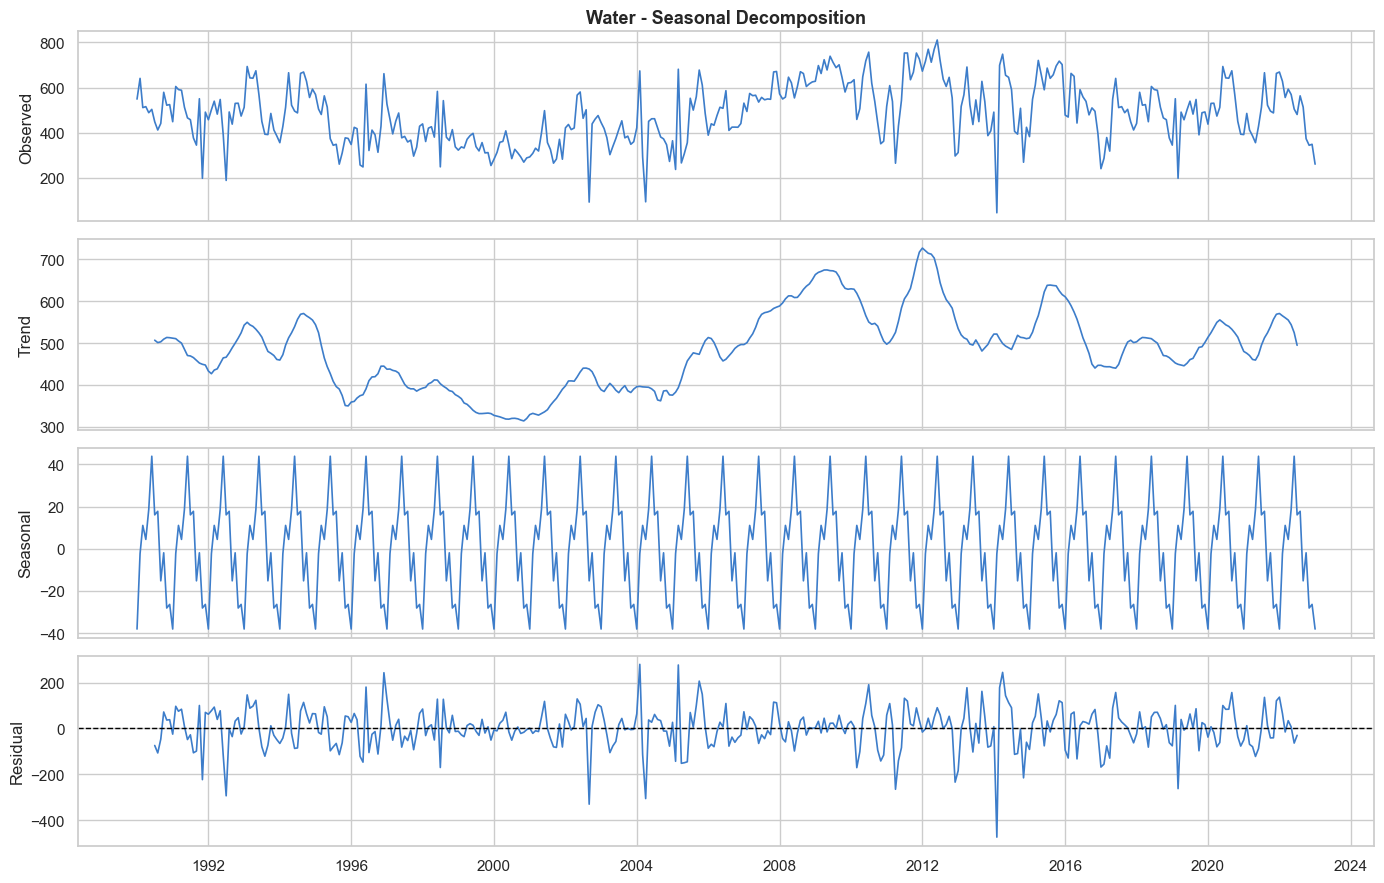

In [7]:
water_dec = plot_decomposition(df[WATER], "Water", COLORS[WATER])

**Water**
- **Trend:** wanders between about **320 and 730 tons** with no consistent direction. It falls to about 320 around 2000, rises to a peak of about 725 in early 2012, then settles near 500.
- **Seasonal:** a small pattern of about −38 to +45 tons, which is **weak** compared with the overall level.
- **Residual:** **very large** (up to about ±470 tons). Most of water's month-to-month variation is **not explained** by trend or season.

Water is mostly irregular, so it will be the **hardest to forecast**.

### Decomposition Summary

| Utility | Trend | Seasonality | Residual noise | Expected forecastability |
|---|---|---|---|---|
| **Gas** | No growth, slowly drifting level | Weak | Low (one spike) | Moderate |
| **Electricity** | Rising, then levelling | **Strong** | Low | **Very good** |
| **Water** | Wandering | Weak | **High** | Poor |

### 2.3 Correlation Between Utilities

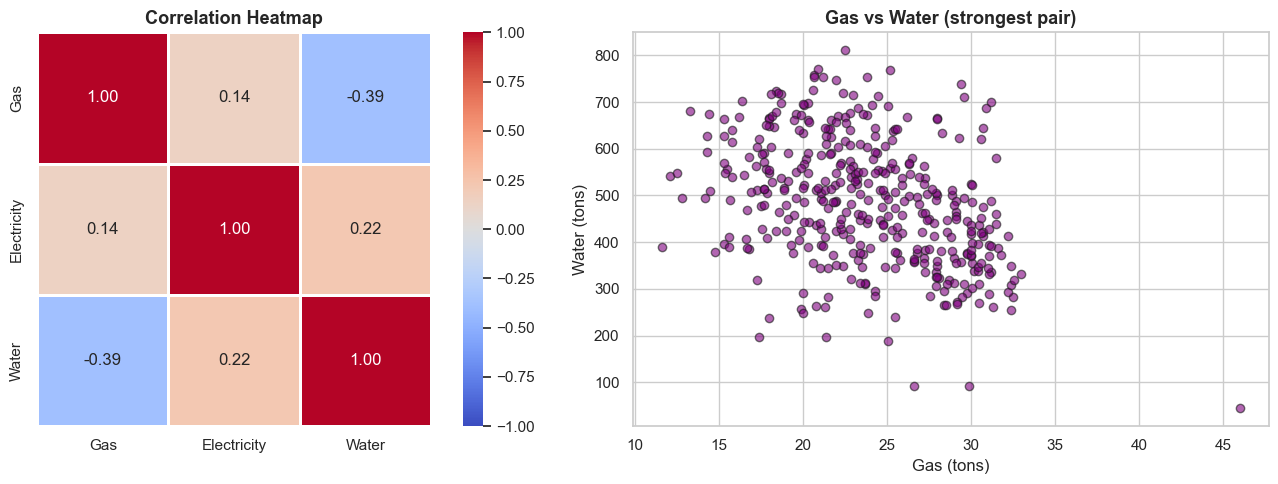

In [8]:
corr = df[UTILITIES].corr()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            linewidths=1, ax=axes[0], xticklabels=["Gas", "Electricity", "Water"], yticklabels=["Gas", "Electricity", "Water"])
axes[0].set_title("Correlation Heatmap", fontsize=13, fontweight="bold")
axes[1].scatter(df[GAS], df[WATER], alpha=0.6, color="purple", edgecolors="k")
axes[1].set_xlabel("Gas (tons)"); axes[1].set_ylabel("Water (tons)")
axes[1].set_title("Gas vs Water (strongest pair)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

| Pair | Correlation | Strength |
|---|---|---|
| Gas ↔ Electricity | +0.14 | Very weak |
| Electricity ↔ Water | +0.22 | Weak |
| Gas ↔ Water | −0.39 | Moderate, negative |

All correlations are **below 0.4 in absolute value**, so the utilities behave largely **independently**. Using one utility to predict another would add little, so each utility gets its **own model**. The moderate negative gas–water link means months with more gas use tend to have slightly less water use. The February 2014 event is an extreme example of this.

## Step 3: Train / Validation / Test Split

Time series data is **not shuffled**. Shuffling would let the model learn from future months to predict past ones (**data leakage**), and a real forecast only ever has the past to work from. The data is split **chronologically**:

- **Train (80%):** fit the candidate models.
- **Validation (10%):** compare models and tune hyperparameters.
- **Test (10%):** used **once**, at the end, to measure performance on unseen data.

In [9]:
train_size = int(len(df) * 0.80)
val_size = int(len(df) * 0.10)
train = df.iloc[:train_size]
val = df.iloc[train_size:train_size + val_size]
test = df.iloc[train_size + val_size:]

split_df = pd.DataFrame({
    "Rows": [len(train), len(val), len(test)],
    "From": [s.index.min().strftime("%b %Y") for s in (train, val, test)],
    "To":   [s.index.max().strftime("%b %Y") for s in (train, val, test)],
}, index=["Train", "Validation", "Test"])
split_df

,Rows,From,To
Train,317,Jan 1990,May 2016
Validation,39,Jun 2016,Aug 2019
Test,41,Sep 2019,Jan 2023


| Set | Rows | Period |
|---|---|---|
| **Train** | 317 | Jan 1990 – May 2016 |
| **Validation** | 39 | Jun 2016 – Aug 2019 |
| **Test** | 41 | Sep 2019 – Jan 2023 |

The training set covers **more than 26 full yearly cycles**, which is plenty for estimating seasonality. It also includes the February 2014 outlier. The validation and test periods are clean, recent data.

## Step 4: Stationarity Check (ADF Test)

ARIMA-type models need a **stationary** series, i.e. one whose mean and variance don't change over time. The **Augmented Dickey-Fuller (ADF)** test checks this:

- **p < 0.05:** the series is stationary, so no differencing is needed (**d = 0**).
- **p ≥ 0.05:** the series is non-stationary, so it is differenced once (**d = 1**) and tested again.

The test is run on the **training set only**, so the decision doesn't use future data.

In [10]:
rows = []
for u in UTILITIES:
    p_orig = adfuller(train[u])[1]
    p_diff = adfuller(train[u].diff().dropna())[1]
    rows.append({"Utility": u, "ADF p-value (original)": round(p_orig, 4),
                 "Stationary?": "Yes" if p_orig < 0.05 else "No",
                 "ADF p-value (1st difference)": round(p_diff, 4)})
adf_df = pd.DataFrame(rows).set_index("Utility")
adf_df

,ADF p-value (original),Stationary?,ADF p-value (1st difference)
Utility,,,
Gas Consumption (tons),0.3158,No,0.0
Electricity Consumption (MWh),0.4113,No,0.0
Water Consumption (tons),0.0095,Yes,0.0


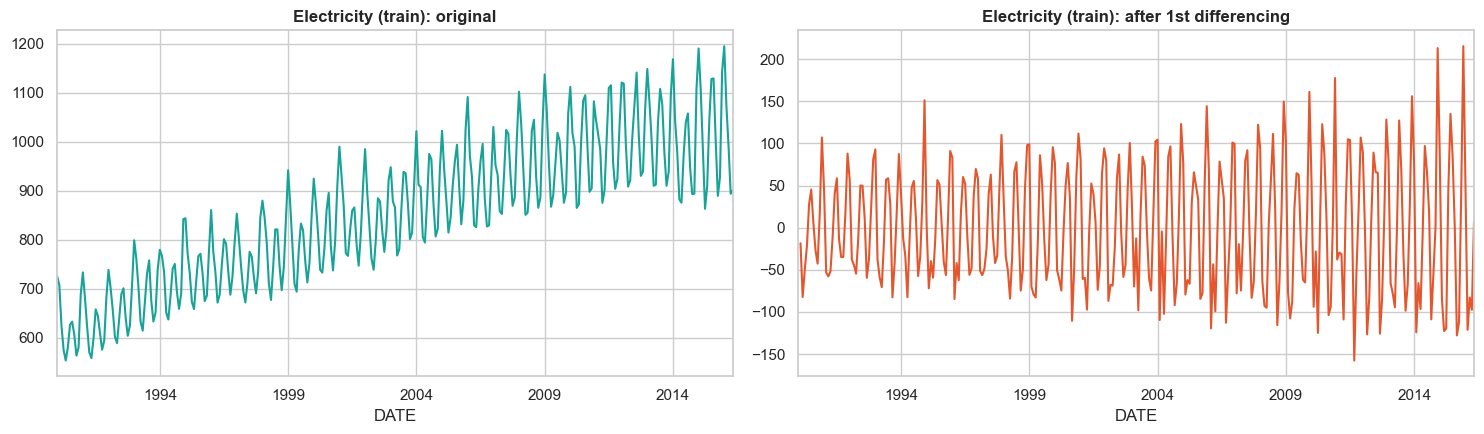

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
train[ELEC].plot(ax=ax[0], color=COLORS[ELEC]); ax[0].set_title("Electricity (train): original", fontweight="bold")
train[ELEC].diff().plot(ax=ax[1], color="#E4572E"); ax[1].set_title("Electricity (train): after 1st differencing", fontweight="bold")
plt.tight_layout()
plt.show()

### Stationarity Results

| Utility | ADF p-value (original) | Stationary? | After 1st difference | Differencing used in models |
|---|---|---|---|---|
| **Gas** | 0.316 | **No** | 0.000 | d = 0 (see note) |
| **Electricity** | 0.411 | **No** | 0.000 | **d = 1**, plus seasonal D = 1 |
| **Water** | **0.0095** | **Yes** | 0.000 | **d = 0** |

- **Electricity** is non-stationary because of its upward trend. One round of differencing removes the trend (p ≈ 0.000), as the plot shows, so its SARIMA models use **d = 1**. They also use a **seasonal difference (D = 1)** to remove the 12-month cycle.
- **Water** is already stationary (p < 0.05). Even though its level wanders, it keeps returning to a stable average, so **d = 0** is appropriate. The water grid search in Step 6 also tests d = 1, and d = 0 still performs best.
- **Gas** is **not stationary** according to the ADF test (p = 0.316). This matches the slowly drifting level seen in the decomposition. The gas models were nevertheless kept at **d = 0**, because ARIMA(1,0,1) gave the best validation results. The consequence is that the gas forecast **reverts to the long-run average**, which is exactly why it under-predicts the higher gas use in 2020–2022 (Step 7). Testing **d = 1** for gas is the most promising improvement for future work.

## Step 5: Baseline Models

Because the utilities behave so differently, **each gets its own set of candidate models**, chosen from the EDA:

| Utility | Pattern | Candidate models |
|---|---|---|
| **Gas** | No long-term growth, weak seasonality | Seasonal Naive, ARIMA(1,0,1), Simple Exponential Smoothing (ETS) |
| **Electricity** | Trend + strong seasonality | Seasonal Naive, SARIMA(0,1,1)(0,1,1)₁₂, Holt-Winters (additive) |
| **Water** | Noisy, no clear pattern | Mean, ARIMA(1,0,1), 12-month Moving Average |

The **Seasonal Naive** (repeat the last 12 months) and **Mean** models act as simple benchmarks. A more complex model is only worth using if it beats them.

**Metrics:**
- **MAE:** average size of the error.
- **RMSE:** like MAE, but penalises large errors more heavily.
- **MAPE:** average percentage error, which allows the three utilities to be compared despite their different units.

In [12]:
def evaluate(actual, predicted, name):
    a, p = np.asarray(actual), np.asarray(predicted)
    return {"Model": name,
            "MAE": mean_absolute_error(a, p),
            "RMSE": np.sqrt(mean_squared_error(a, p)),
            "MAPE (%)": np.mean(np.abs((a - p) / a)) * 100}

def seasonal_naive(train_s, steps):
    return np.tile(train_s[-12:].values, steps // 12 + 1)[:steps]

h = len(val)
tr_gas, va_gas = train[GAS], val[GAS]
tr_elec, va_elec = train[ELEC], val[ELEC]
tr_water, va_water = train[WATER], val[WATER]

gas_df = pd.DataFrame([
    evaluate(va_gas, seasonal_naive(tr_gas, h), "Seasonal Naive"),
    evaluate(va_gas, ARIMA(tr_gas, order=(1, 0, 1)).fit().forecast(h), "ARIMA(1,0,1)"),
    evaluate(va_gas, ExponentialSmoothing(tr_gas, trend=None, seasonal=None).fit().forecast(h), "ETS"),
])
elec_df = pd.DataFrame([
    evaluate(va_elec, seasonal_naive(tr_elec, h), "Seasonal Naive"),
    evaluate(va_elec, SARIMAX(tr_elec, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(h), "SARIMA(0,1,1)(0,1,1,12)"),
    evaluate(va_elec, ExponentialSmoothing(tr_elec, trend="add", seasonal="add", seasonal_periods=12).fit().forecast(h), "Holt-Winters"),
])
water_df = pd.DataFrame([
    evaluate(va_water, np.full(h, tr_water.mean()), "Mean"),
    evaluate(va_water, ARIMA(tr_water, order=(1, 0, 1)).fit().forecast(h), "ARIMA(1,0,1)"),
    evaluate(va_water, np.full(h, tr_water[-12:].mean()), "Moving Average (12)"),
])

for name, d in [("GAS", gas_df), ("ELECTRICITY", elec_df), ("WATER", water_df)]:
    print(f"\n{name} (validation set)")
    print(d.round(2).to_string(index=False))


GAS (validation set)
         Model  MAE  RMSE  MAPE (%)
Seasonal Naive 5.33  6.27     22.53
  ARIMA(1,0,1) 3.21  3.91     15.39
           ETS 5.50  6.27     22.80

ELECTRICITY (validation set)
                  Model   MAE  RMSE  MAPE (%)
         Seasonal Naive 30.57 37.02      2.95
SARIMA(0,1,1)(0,1,1,12) 23.39 29.50      2.22
           Holt-Winters 28.70 34.04      2.77

WATER (validation set)
              Model    MAE   RMSE  MAPE (%)
               Mean  73.32  98.55     19.72
       ARIMA(1,0,1)  71.69  99.11     19.67
Moving Average (12) 142.04 171.63     38.12


### Baseline Results (Validation Set)

| Utility | Best baseline | RMSE | MAPE | Simple benchmark |
|---|---|---|---|---|
| **Gas** | **ARIMA(1,0,1)** | 3.91 | 15.39% | Seasonal Naive: 6.27 / 22.53% |
| **Electricity** | **SARIMA(0,1,1)(0,1,1)₁₂** | 29.50 | 2.22% | Seasonal Naive: 37.02 / 2.95% |
| **Water** | **Mean** | 98.55 | 19.72% | ARIMA(1,0,1): 99.11 / 19.67% |

- **Gas:** ARIMA clearly beats both Seasonal Naive and ETS. ETS performs no better than Seasonal Naive.
- **Electricity:** SARIMA is the most accurate, ahead of Holt-Winters (34.04) and Seasonal Naive. Even the simple Seasonal Naive model is accurate (2.95%), which shows how strong and regular electricity's seasonal pattern is.
- **Water:** **no model beats simply predicting the training average.** ARIMA(1,0,1) is essentially equal to the Mean, and the 12-month Moving Average is much worse (38% MAPE). This confirms the EDA finding that water's history contains very little usable pattern.

## Step 6: Hyperparameter Tuning (Grid Search on Validation Set)

Each model's order parameters are searched systematically. The combination with the **lowest validation RMSE** is kept.

### 6.1 Gas: ARIMA(p, 0, q)

In [13]:
def grid_search(fit_fn, configs, actual):
    rows = []
    for cfg in configs:
        try:
            rows.append({**evaluate(actual, fit_fn(cfg), str(cfg)), "cfg": cfg})
        except Exception:
            pass
    return pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)

gas_grid = grid_search(lambda o: ARIMA(tr_gas, order=o).fit().forecast(h),
                       [(p, 0, q) for p in range(4) for q in range(4) if (p, q) != (0, 0)], va_gas)
best_gas_order = gas_grid.loc[0, "cfg"]
print("Top 5 gas configurations:")
print(gas_grid.drop(columns="cfg").head().round(2).to_string(index=False))
print(f"\nBest: ARIMA{best_gas_order}")

Top 5 gas configurations:
    Model  MAE  RMSE  MAPE (%)
(1, 0, 1) 3.21  3.91     15.39
(1, 0, 2) 3.25  3.96     14.69
(3, 0, 0) 3.28  3.99     15.86
(2, 0, 0) 3.32  4.05     16.15
(1, 0, 0) 3.43  4.21     16.89

Best: ARIMA(1, 0, 1)


### 6.2 Electricity: SARIMA(p, 1, q)(P, 1, Q)₁₂

In [14]:
elec_configs = [((p, 1, q), (P, 1, Q, 12)) for p in range(3) for q in range(3) for P in range(2) for Q in range(2)
                if (p, q) != (0, 0) and (P, Q) != (0, 0)]
elec_grid = grid_search(lambda c: SARIMAX(tr_elec, order=c[0], seasonal_order=c[1]).fit(disp=False).forecast(h),
                        elec_configs, va_elec)
best_elec_order, best_elec_seasonal = elec_grid.loc[0, "cfg"]
print("Top 5 electricity configurations:")
print(elec_grid.drop(columns="cfg").head().round(2).to_string(index=False))
print(f"\nBest: SARIMA{best_elec_order}{best_elec_seasonal}")

Top 5 electricity configurations:
                     Model   MAE  RMSE  MAPE (%)
((0, 1, 1), (1, 1, 1, 12)) 23.35 29.47      2.22
((0, 1, 1), (0, 1, 1, 12)) 23.39 29.50      2.22
((2, 1, 0), (1, 1, 1, 12)) 23.47 29.68      2.23
((2, 1, 0), (0, 1, 1, 12)) 23.59 29.78      2.24
((1, 1, 0), (1, 1, 1, 12)) 23.42 29.81      2.23

Best: SARIMA(0, 1, 1)(1, 1, 1, 12)


### 6.3 Water: ARIMA(p, d, q)

In [15]:
water_grid = grid_search(lambda o: ARIMA(tr_water, order=o).fit().forecast(h),
                         [(p, d, q) for p in range(4) for d in (0, 1) for q in range(4) if (p, q) != (0, 0)], va_water)
best_water_order = water_grid.loc[0, "cfg"]
print("Top 5 water configurations:")
print(water_grid.drop(columns="cfg").head().round(2).to_string(index=False))
print(f"\nBest: ARIMA{best_water_order}")

Top 5 water configurations:
    Model   MAE  RMSE  MAPE (%)
(3, 0, 0) 72.04 98.20     19.57
(2, 0, 0) 73.12 98.34     19.68
(1, 0, 1) 71.69 99.11     19.67
(1, 1, 0) 72.05 99.76     19.91
(1, 0, 0) 74.70 99.77     19.95

Best: ARIMA(3, 0, 0)


In [16]:
tuning_df = pd.DataFrame({
    "Utility": ["Gas", "Electricity", "Water"],
    "Baseline model": ["ARIMA(1,0,1)", "SARIMA(0,1,1)(0,1,1,12)", "ARIMA(1,0,1)"],
    "Baseline RMSE": [gas_df.loc[1, "RMSE"], elec_df.loc[1, "RMSE"], water_df.loc[1, "RMSE"]],
    "Tuned model": [f"ARIMA{best_gas_order}", f"SARIMA{best_elec_order}{best_elec_seasonal}", f"ARIMA{best_water_order}"],
    "Tuned RMSE": [gas_grid.loc[0, "RMSE"], elec_grid.loc[0, "RMSE"], water_grid.loc[0, "RMSE"]],
    "Tuned MAPE (%)": [gas_grid.loc[0, "MAPE (%)"], elec_grid.loc[0, "MAPE (%)"], water_grid.loc[0, "MAPE (%)"]],
})
tuning_df["RMSE change (%)"] = (tuning_df["Baseline RMSE"] - tuning_df["Tuned RMSE"]) / tuning_df["Baseline RMSE"] * 100
tuning_df.round(2)

,Utility,Baseline model,Baseline RMSE,Tuned model,Tuned RMSE,Tuned MAPE (%),RMSE change (%)
0,Gas,"ARIMA(1,0,1)",3.91,"ARIMA(1, 0, 1)",3.91,15.39,0.00
1,Electricity,"SARIMA(0,1,1)(0,1,1,12)",29.50,"SARIMA(0, 1, 1)(1, 1, 1, 12)",29.47,2.22,0.12
2,Water,"ARIMA(1,0,1)",99.11,"ARIMA(3, 0, 0)",98.20,19.57,0.92


### Tuning Results

| Utility | Baseline → Tuned | Validation RMSE | Validation MAPE |
|---|---|---|---|
| **Gas** | ARIMA(1,0,1) → **ARIMA(1,0,1)** | 3.91 → 3.91 | 15.39% |
| **Electricity** | SARIMA(0,1,1)(0,1,1)₁₂ → **SARIMA(0,1,1)(1,1,1)₁₂** | 29.50 → 29.47 | 2.22% |
| **Water** | ARIMA(1,0,1) → **ARIMA(3,0,0)** | 99.11 → 98.20 | 19.57% |

- **Gas:** the original ARIMA(1,0,1) was already the best of all 15 configurations.
- **Electricity:** adding a seasonal AR term made almost no difference (−0.1% RMSE).
- **Water:** ARIMA(3,0,0) gives a small gain (−0.9% RMSE). It is only just better than predicting the **training mean (98.55)**, so the improvement is not meaningful.

Tuning **confirmed** the initial model choices rather than finding much better ones. The choice of model *type* (from the EDA) mattered far more than the exact parameter values.

## Step 7: Final Evaluation on the Test Set

Each tuned model is **retrained on train + validation** (all data before September 2019), then evaluated once on the unseen test period (**September 2019 – January 2023**).

In [17]:
trval = pd.concat([train, val])
ht = len(test)
final_specs = {
    GAS:   ("ARIMA" + str(best_gas_order), lambda s: ARIMA(s, order=best_gas_order).fit()),
    ELEC:  (f"SARIMA{best_elec_order}{best_elec_seasonal}", lambda s: SARIMAX(s, order=best_elec_order, seasonal_order=best_elec_seasonal).fit(disp=False)),
    WATER: ("ARIMA" + str(best_water_order), lambda s: ARIMA(s, order=best_water_order).fit()),
}
val_best = {GAS: gas_grid.loc[0], ELEC: elec_grid.loc[0], WATER: water_grid.loc[0]}

test_forecasts, rows = {}, []
for u, (name, fit) in final_specs.items():
    fc = fit(trval[u]).forecast(ht)
    test_forecasts[u] = fc
    r = evaluate(test[u], fc, name)
    rows.append({"Utility": u.split(" ")[0], "Model": name,
                 "Val RMSE": val_best[u]["RMSE"], "Val MAPE (%)": val_best[u]["MAPE (%)"],
                 "Test MAE": r["MAE"], "Test RMSE": r["RMSE"], "Test MAPE (%)": r["MAPE (%)"],
                 "Bias (mean error)": float(np.mean(test[u].values - fc.values))})
final_df = pd.DataFrame(rows)
final_df.round(2)

,Utility,Model,Val RMSE,Val MAPE (%),Test MAE,Test RMSE,Test MAPE (%),Bias (mean error)
0,Gas,"ARIMA(1, 0, 1)",3.91,15.39,4.16,5.06,15.03,3.39
1,Electricity,"SARIMA(0, 1, 1)(1, 1, 1, 12)",29.47,2.22,35.00,44.46,3.30,26.60
2,Water,"ARIMA(3, 0, 0)",98.20,19.57,85.34,106.57,17.79,20.00


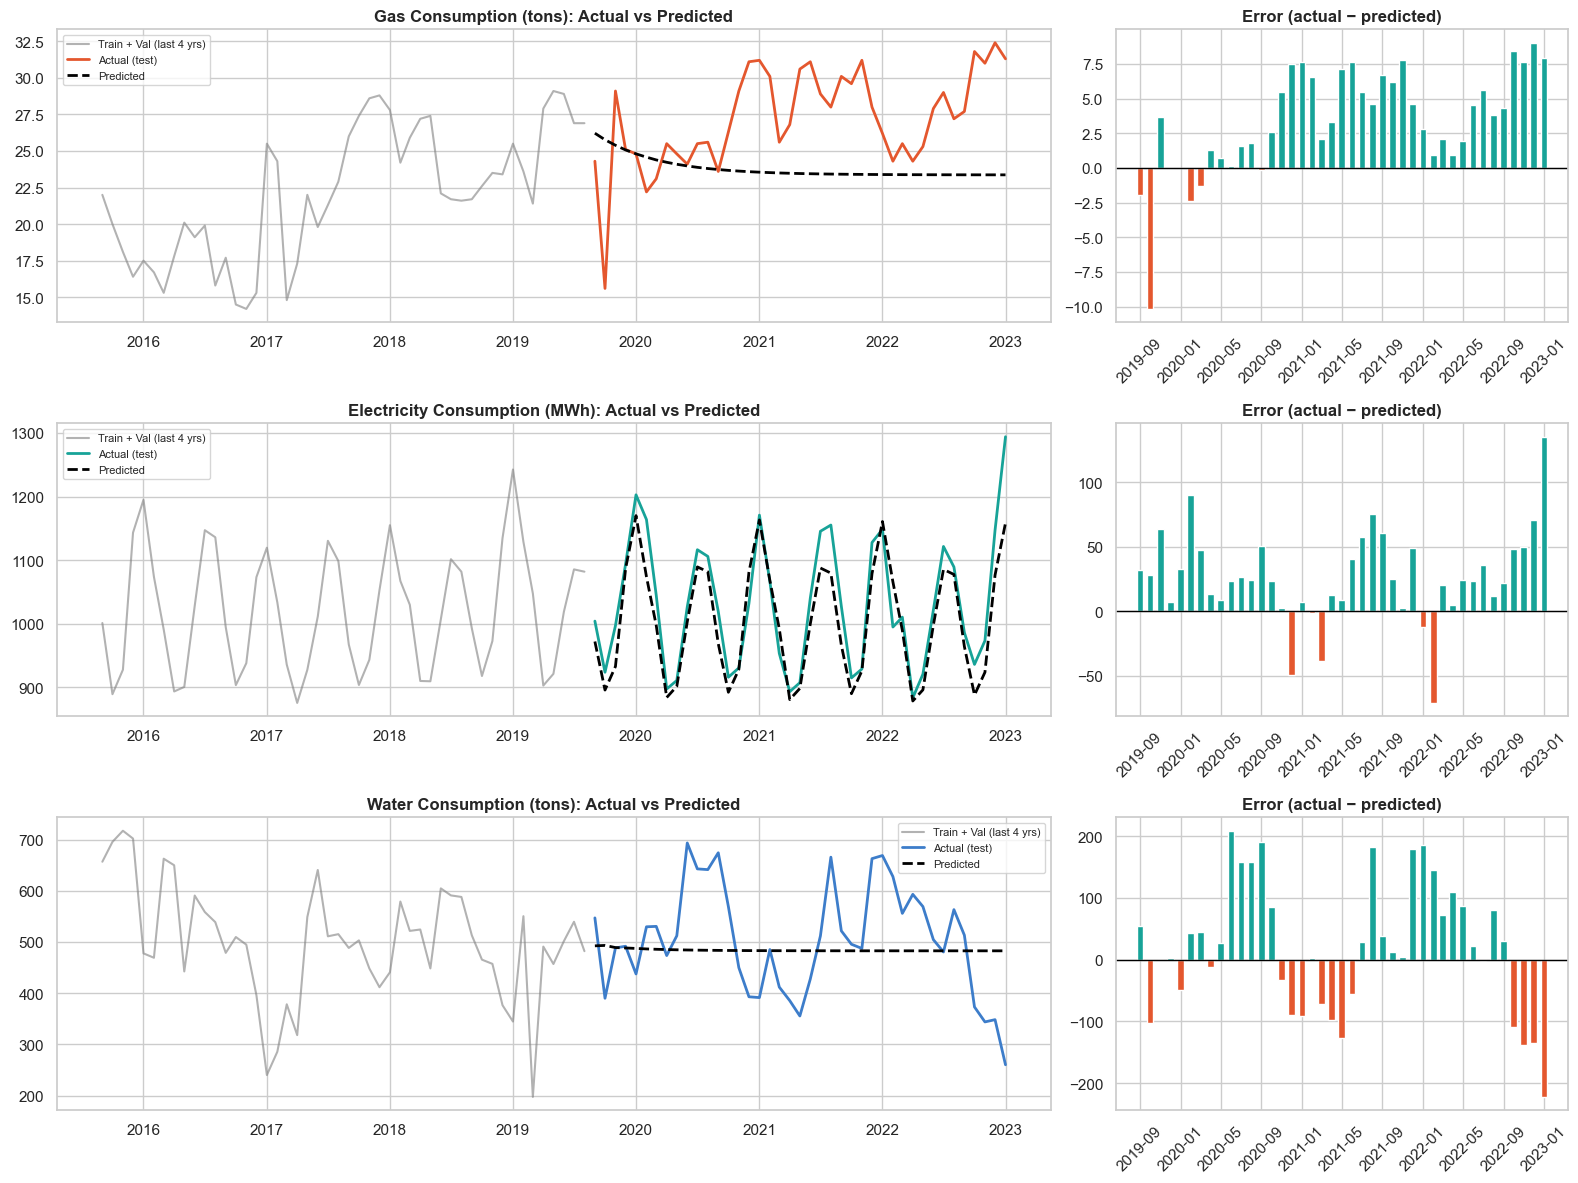

In [18]:
fig, axes = plt.subplots(3, 2, figsize=(16, 12), gridspec_kw={"width_ratios": [2.2, 1]})
for i, u in enumerate(UTILITIES):
    axes[i, 0].plot(trval[u].iloc[-48:].index, trval[u].iloc[-48:], color="grey", alpha=0.6, label="Train + Val (last 4 yrs)")
    axes[i, 0].plot(test.index, test[u], color=COLORS[u], linewidth=2, label="Actual (test)")
    axes[i, 0].plot(test.index, test_forecasts[u], color="black", linestyle="--", linewidth=2, label="Predicted")
    axes[i, 0].set_title(f"{u}: Actual vs Predicted", fontweight="bold"); axes[i, 0].legend(fontsize=8)
    err = test[u].values - test_forecasts[u].values
    axes[i, 1].bar(test.index, err, width=20, color=np.where(err >= 0, "#17A398", "#E4572E"))
    axes[i, 1].axhline(0, color="black", linewidth=1)
    axes[i, 1].set_title("Error (actual − predicted)", fontweight="bold")
    axes[i, 1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### Test Set Results

| Utility | Final model | Validation MAPE | **Test MAPE** | Test RMSE | Bias (actual − predicted) |
|---|---|---|---|---|---|
| **Gas** | ARIMA(1,0,1) | 15.39% | **15.03%** | 5.06 | +3.39 tons |
| **Electricity** | SARIMA(0,1,1)(1,1,1)₁₂ | 2.22% | **3.30%** | 44.46 | +26.60 MWh |
| **Water** | ARIMA(3,0,0) | 19.57% | **17.79%** | 106.57 | +20.00 tons |

A **positive bias** means the actual values were, on average, **higher than predicted**, so all three models under-predict slightly.

- **Electricity** is forecast very accurately (**3.3% MAPE**). The predicted line follows the yearly peaks and troughs almost exactly. Most errors are positive, meaning actual use was a little higher than forecast, and the largest miss is **January 2023** (about +135 MWh), when consumption hit a record 1,294 MWh.
- **Gas** has a consistent MAPE (about 15% on both validation and test), but the forecast **settles at about 23.4 tons**, while actual use **rose to 28–32 tons in 2021–2022**. Almost every error from late 2020 onwards is positive. This is the effect of the non-stationary, drifting level found by the ADF test.
- **Water** reaches 17.8% MAPE, but its forecast is essentially a **flat line at about 480 tons**. Actual use swings between about 260 and 690 tons, with long runs of positive and negative errors. **Monthly water use is mostly unpredictable** from its own history.

Gas and water have similar MAPE on validation and test. Electricity's error rises from 2.2% to 3.3% but stays very low, so all three models **generalise** reasonably to unseen data.

## Step 8: 60-Month Forecast

Each final model is **retrained on the full dataset** (January 1990 – January 2023) and used to forecast the **next 60 months**, with **95% confidence intervals**.

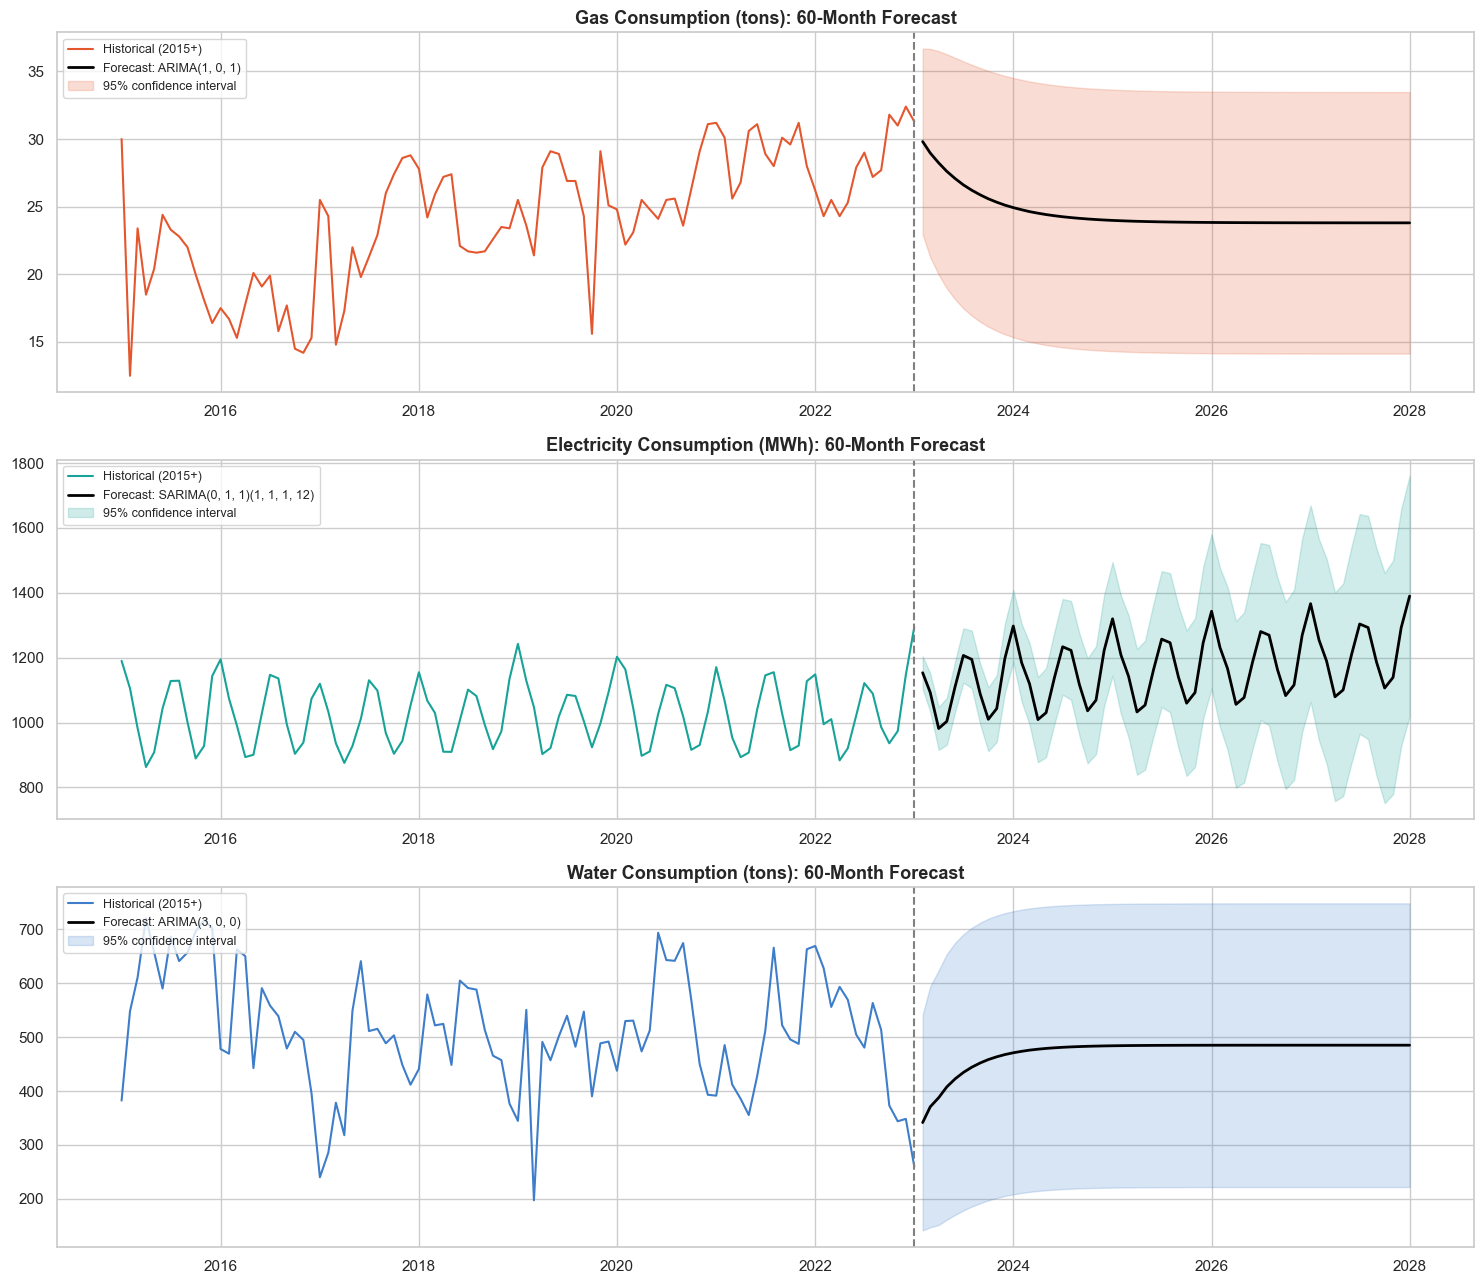

Forecast period: Feb 2023 – Jan 2028


,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
Year (avg per month),,,
2023,26.9,1098.6,422.7
2024,24.4,1140.0,479.3
2025,23.9,1163.4,484.5
2026,23.8,1186.8,484.9
2027,23.8,1210.1,485.0
2028,23.8,1389.8,485.0


In [19]:
H = 60
forecast_rows = {}
fig, axes = plt.subplots(3, 1, figsize=(15, 13))
for ax, u in zip(axes, UTILITIES):
    name, fit = final_specs[u]
    res = fit(df[u]).get_forecast(H)
    mean, ci = res.predicted_mean, res.conf_int(alpha=0.05)
    forecast_rows[u] = mean
    hist = df[u].loc["2015":]
    ax.plot(hist.index, hist, color=COLORS[u], linewidth=1.5, label="Historical (2015+)")
    ax.plot(mean.index, mean, color="black", linewidth=2, label=f"Forecast: {name}")
    ax.fill_between(mean.index, ci.iloc[:, 0], ci.iloc[:, 1], color=COLORS[u], alpha=0.2, label="95% confidence interval")
    ax.axvline(df.index[-1], color="grey", linestyle="--")
    ax.set_title(f"{u}: 60-Month Forecast", fontsize=13, fontweight="bold"); ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

forecast_df = pd.DataFrame(forecast_rows)
print(f"Forecast period: {forecast_df.index.min():%b %Y} – {forecast_df.index.max():%b %Y}")
yearly = forecast_df.groupby(forecast_df.index.year).mean().round(1)
yearly.index.name = "Year (avg per month)"
yearly

### Forecast Interpretation (February 2023 – January 2028)

| Year | Gas (tons/month) | Electricity (MWh/month) | Water (tons/month) |
|---|---|---|---|
| 2023 (Feb–Dec) | 26.9 | 1,099 | 423 |
| 2024 | 24.4 | 1,140 | 479 |
| 2025 | 23.9 | 1,163 | 485 |
| 2026 | 23.8 | 1,187 | 485 |
| 2027 | 23.8 | 1,210 | 485 |

*2028 only contains January, a seasonal peak month, so its average (1,390 MWh) is not comparable and is left out.*

- **Electricity** keeps its strong seasonal pattern and **rises about 2% per year** (1,140 → 1,210 MWh per month). Note that the long-term trend had **levelled off since about 2013**, while the SARIMA model's differencing carries the most recent upward movement forward. The growth projection is therefore likely **optimistic**, and the confidence band widens noticeably over time.
- **Gas** starts near recent levels (about 27 tons) and then **falls back to its long-run average of about 24 tons**. Given the rising gas use in 2021–2022, this is likely an **under-estimate**.
- **Water** settles at its **historical average of about 485 tons** per month, with a **very wide** confidence band, which reflects how unpredictable water use is.

**Planning implications**
1. **Electricity:** budget for seasonal peaks, especially January, using this forecast. Treat the 2% annual growth as an upper scenario.
2. **Gas:** recent use has been about 15–25% above the forecast level, so budget nearer to recent actuals (28–30 tons) and monitor.
3. **Water:** treat the forecast as a rough average only. The bigger opportunity is to **investigate and control** the causes of its large swings.

## Step 9: Model Improvement Analysis
### 9.1 Impact of Seasonality

Each utility's model is compared **with and without** a seasonal component on the validation set.

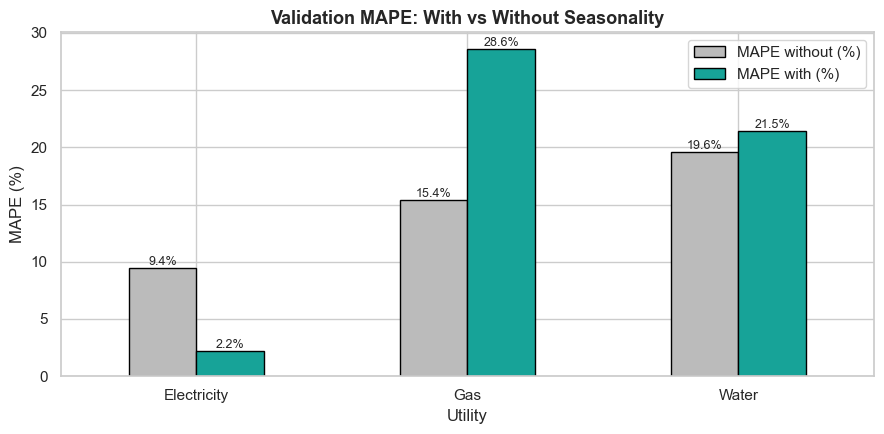

,MAPE without (%),MAPE with (%),RMSE without,RMSE with
Utility,,,,
Electricity,9.42,2.22,127.53,29.50
Gas,15.39,28.62,3.91,8.02
Water,19.57,21.45,98.20,108.29


In [20]:
season_rows = []
pairs = [
    (ELEC, ARIMA(tr_elec, order=(0, 1, 1)), SARIMAX(tr_elec, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))),
    (GAS, ARIMA(tr_gas, order=best_gas_order), SARIMAX(tr_gas, order=best_gas_order, seasonal_order=(1, 0, 1, 12))),
    (WATER, ARIMA(tr_water, order=best_water_order), SARIMAX(tr_water, order=best_water_order, seasonal_order=(1, 0, 1, 12))),
]
for u, m_no, m_yes in pairs:
    no = evaluate(val[u], m_no.fit().forecast(h), "No seasonality")
    yes = evaluate(val[u], m_yes.fit(disp=False).forecast(h), "With seasonality")
    season_rows.append({"Utility": u.split(" ")[0], "MAPE without (%)": no["MAPE (%)"], "MAPE with (%)": yes["MAPE (%)"],
                        "RMSE without": no["RMSE"], "RMSE with": yes["RMSE"]})
season_df = pd.DataFrame(season_rows).set_index("Utility")

ax = season_df[["MAPE without (%)", "MAPE with (%)"]].plot(kind="bar", figsize=(9, 4.5), color=["#BBBBBB", "#17A398"], edgecolor="black")
for c in ax.containers: ax.bar_label(c, fmt="%.1f%%", fontsize=9)
plt.title("Validation MAPE: With vs Without Seasonality", fontsize=13, fontweight="bold")
plt.ylabel("MAPE (%)"); plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
season_df.round(2)

| Utility | MAPE without seasonality | MAPE with seasonality | Effect |
|---|---|---|---|
| **Electricity** | 9.42% | **2.22%** | **76% lower error** |
| **Gas** | **15.39%** | 28.62% | Worse |
| **Water** | **19.57%** | 21.45% | Worse |

- **Electricity:** adding seasonality cut the error from **9.42% to 2.22%**, a 7.2 percentage-point drop or **76% in relative terms**. This is the **single biggest improvement in the project**, and it reflects electricity's strong yearly cycle.
- **Gas and Water:** adding seasonality made the forecasts **worse**. These utilities have only a weak seasonal pattern (as seen in the EDA), so the extra seasonal parameters end up fitting noise.

**Takeaway:** only add seasonality when the data actually shows a seasonal pattern.

### 9.2 Impact of Hyperparameter Tuning
As shown in Step 6, tuning changed validation RMSE by **less than 1%** for every utility. Overall, **choosing the right type of model** (seasonal or not, based on the EDA) mattered far more than fine-tuning its parameters.

## Final Conclusion

This project forecast monthly gas, electricity and water consumption using **33 years of data (1990–2023)**.

- **EDA** showed that the three utilities behave very differently and are only weakly correlated, so each one was modelled separately:
  - **Electricity:** rising trend that levels off after about 2013, with strong seasonality
  - **Gas:** no long-term growth, but a slowly drifting level
  - **Water:** mostly irregular noise
- A **chronological 80/10/10 split** avoided data leakage. Candidate models were compared against simple benchmarks (Seasonal Naive and Mean).
- **Final models and test-set performance:**

| Utility | Model | Test MAPE |
|---|---|---|
| Electricity | SARIMA(0,1,1)(1,1,1)₁₂ | **3.30%** |
| Gas | ARIMA(1,0,1) | 15.03% |
| Water | ARIMA(3,0,0) | 17.79% |

- **Including seasonality for electricity** was the most important modelling decision (76% lower error). Hyperparameter tuning changed results by less than 1%.

### Limitations & Future Work
- **Gas:** the ADF test showed gas is non-stationary (p = 0.32), but the models used d = 0. As a result, the forecast reverts to the long-run average and under-predicted the higher use in 2021–2022. Testing **ARIMA with d = 1**, or re-fitting regularly on recent data, should improve it.
- **Electricity:** the 60-month forecast extends recent growth although the long-term trend has flattened. A damped-trend model could give a more conservative projection.
- **Water** forecasts are barely better than the historical mean. External factors such as occupancy, weather or operations data would be needed to predict it properly.
- The **February 2014 event** (gas spike and water drop at the same time) should be checked with the facility to confirm whether it was a real event or a data error.
- Rolling-origin (walk-forward) validation would give a more reliable estimate of forecast accuracy than a single validation window.